# Wheat_analysis — qualité des données, mise en forme mensuelle et corrélations

**Objectif** : modéliser le cours du blé à partir de variables météo, de sentiment de marché, du dollar et du pétrole. Ce notebook prépare le terrain pour les régressions :

1. **Chargement** des 5 variables (blé, sentiment WASDE, RONI, dollar, WTI)
2. **Qualité des données** (fréquence, couverture, trous, doublons, valeurs aberrantes)
3. **Mise à fréquence mensuelle** puis **centrage-réduction**
4. **Étude des corrélations** (niveaux, variations, décalages temporels, stabilité)

| Variable | Source | Fréquence native |
|---|---|---|
| `wheat_price_usd` — prix du blé (USD/t) | FMI, série PWHEAMT | mensuelle |
| `wasde_sentiment` — score NLP du marché | rapports WASDE de l'USDA (PDF locaux), lexique Loughran-McDonald adapté au blé | ~1 rapport/mois, dates irrégulières |
| `roni_index` — favorabilité météo macro (El Niño / La Niña) | NOAA CPC, indice RONI | mensuelle (moyenne glissante sur 3 mois) |
| `dxy_index` — dollar | FRED : DTWEXM (jusqu'en 2019) raccordé à DTWEXBGS | quotidienne |
| `wti_price_usd` — pétrole | FRED : DCOILWTICO | quotidienne |

> **Sources et clé FRED.** Les téléchargements sont mis en cache dans `data/cache/` (mettre `REFRESH = True` pour les refaire). Le téléchargement FRED nécessite la variable d'environnement `FRED_API_KEY` ; elle n'est pas écrite dans le notebook. Le sentiment WASDE est recalculé ici à partir des fichiers de `data/wasde_txt_reports/` avec les mêmes règles de scoring que le notebook `Wheat_Data.ipynb`, mais avec une **datation corrigée** (voir §1.3).

In [1]:
import logging
import os
import re
from io import StringIO
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
import requests
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from pypdf import PdfReader

logging.getLogger("pypdf").setLevel(logging.ERROR)
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)

DATA_DIR = Path("./data")
CACHE_DIR = DATA_DIR / "cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)
WASDE_DIR = DATA_DIR / "wasde_txt_reports"
START, END = "1992-01-01", "2026-12-31"
REFRESH = False  # True : retélécharge les sources au lieu de lire data/cache/

# --- Style graphique : une couleur par variable, toujours la même ---
INK, INK2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
COLORS = {
    "wheat_price_usd": "#2a78d6",   # bleu
    "wasde_sentiment": "#eb6834",   # orange
    "roni_index": "#1baf7a",        # aqua
    "dxy_index": "#eda100",         # jaune
    "wti_price_usd": "#e87ba4",     # magenta
}
LABELS = {
    "wheat_price_usd": "Prix du blé (USD/t)",
    "wasde_sentiment": "Sentiment WASDE (score net, -1 à +1)",
    "roni_index": "RONI (°C)",
    "dxy_index": "Dollar (indice large)",
    "wti_price_usd": "Pétrole WTI (USD/baril)",
}
SHORT = {"wheat_price_usd": "Blé", "wasde_sentiment": "Sentiment", "roni_index": "RONI",
         "dxy_index": "Dollar", "wti_price_usd": "WTI"}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 11,
    "axes.titlelocation": "left", "font.size": 10, "lines.linewidth": 1.6,
    "legend.frameon": False, "figure.dpi": 100,
})

## 1. Chargement des données brutes

### 1.1 Blé (FMI), RONI (NOAA), dollar et pétrole (FRED)

In [2]:
def cached(name, builder):
    path = CACHE_DIR / name
    if path.exists() and not REFRESH:
        return pd.read_csv(path, parse_dates=["date"])
    frame = builder()
    frame.to_csv(path, index=False)
    return frame


# ---------- Blé : FMI (SDMX) ----------
IMF_URL = (
    "https://api.imf.org/external/sdmx/3.0/data/dataflow/IMF.RES/PCPS/9.0.0/"
    f"*.PWHEAMT.USD.M?c%5BTIME_PERIOD%5D=ge:1956-12-31+le:{END}"
    "&attributes=all&detail=full&includeHistory=true&limit=100"
)

def fetch_imf_wheat():
    r = requests.get(IMF_URL, headers={"Accept": "application/vnd.sdmx.data+json;version=2.0.0"}, timeout=60)
    r.raise_for_status()
    data = r.json()["data"]
    periods = data["structures"][0]["dimensions"]["observation"][0]["values"]
    series = list(data["dataSets"][0]["series"].values())
    if len(series) != 1:
        raise ValueError(f"Une seule série attendue, {len(series)} reçues")
    rows = [
        {"date": pd.to_datetime(periods[int(i)]["value"].replace("-M", "-"), format="%Y-%m"),
         "wheat_price_usd": pd.to_numeric(obs[0], errors="coerce")}
        for i, obs in series[0]["observations"].items()
    ]
    out = pd.DataFrame(rows).sort_values("date").reset_index(drop=True)
    return out[out["date"] >= START]


# ---------- RONI : NOAA CPC ----------
RONI_URL = "https://www.cpc.ncep.noaa.gov/products/analysis_monitoring/enso/roni/"
SEASON_END_MONTH = {"DJF": 2, "JFM": 3, "FMA": 4, "MAM": 5, "AMJ": 6, "MJJ": 7,
                    "JJA": 8, "JAS": 9, "ASO": 10, "SON": 11, "OND": 12, "NDJ": 1}

def fetch_roni():
    page = requests.get(RONI_URL, timeout=60)
    page.raise_for_status()
    # La table utile est la seule dont les colonnes sont les saisons DJF ... NDJ
    table = next(t for t in pd.read_html(StringIO(page.text))
                 if {"DJF", "NDJ"} <= {str(c).split()[0] for c in t.columns})
    table = table.rename(columns={table.columns[0]: "year"})
    long = table.melt(id_vars="year", var_name="season_label", value_name="roni_index")
    long["year"] = pd.to_numeric(long["year"], errors="coerce")
    long["roni_index"] = pd.to_numeric(long["roni_index"], errors="coerce")
    long = long.dropna(subset=["year"])
    # Une valeur trimestrielle est rattachée à son dernier mois (NDJ de l'année Y -> janvier Y+1)
    long["month"] = long["season_label"].str.split().str[0].map(SEASON_END_MONTH)
    long["date"] = pd.to_datetime({"year": long["year"].astype(int) + long["month"].eq(1),
                                   "month": long["month"], "day": 1})
    return long.loc[long["date"] >= START, ["date", "roni_index"]].sort_values("date").reset_index(drop=True)


# ---------- Dollar et pétrole : FRED ----------
FRED_URL = "https://api.stlouisfed.org/fred/series/observations"

def fetch_fred(series_id, column):
    key = os.environ.get("FRED_API_KEY")
    if not key:
        raise RuntimeError("Définir la variable d'environnement FRED_API_KEY "
                           "(ou fournir le cache data/cache/).")
    r = requests.get(FRED_URL, params={"series_id": series_id, "api_key": key,
                                       "file_type": "json", "observation_start": START}, timeout=60)
    r.raise_for_status()
    obs = pd.DataFrame(r.json()["observations"])[["date", "value"]].rename(columns={"value": column})
    obs["date"] = pd.to_datetime(obs["date"])
    obs[column] = pd.to_numeric(obs[column], errors="coerce")  # FRED code les jours sans cotation par "."
    return obs


wheat_raw = cached("imf_wheat.csv", fetch_imf_wheat)
roni_raw = cached("noaa_roni.csv", fetch_roni)
dxy_history_raw = cached("fred_dtwexm.csv", lambda: fetch_fred("DTWEXM", "dxy_history"))
dxy_current_raw = cached("fred_dtwexbgs.csv", lambda: fetch_fred("DTWEXBGS", "dxy_current"))
wti_raw = cached("fred_wti.csv", lambda: fetch_fred("DCOILWTICO", "wti_price_usd"))

for name, frame in {"blé": wheat_raw, "RONI": roni_raw, "dollar (historique)": dxy_history_raw,
                    "dollar (courant)": dxy_current_raw, "WTI": wti_raw}.items():
    print(f"{name:22s} {len(frame):5d} lignes  {frame['date'].min():%Y-%m-%d} -> {frame['date'].max():%Y-%m-%d}")

blé                      418 lignes  1992-01-01 -> 2026-10-01
RONI                     421 lignes  1992-01-01 -> 2027-01-01
dollar (historique)     7305 lignes  1992-01-01 -> 2019-12-31
dollar (courant)        5440 lignes  2006-01-02 -> 2026-11-06
WTI                     9090 lignes  1992-01-01 -> 2026-11-03


### 1.2 Sentiment WASDE (NLP)

Les rapports mensuels WASDE de l'USDA ont été téléchargés en PDF puis réduits aux paragraphes mentionnant le blé (`*_wheat.txt`). Le score est le *net sentiment* lexical : (mots haussiers − mots baissiers) / (mots haussiers + mots baissiers), de −1 (baissier pour le prix) à +1 (haussier). Les listes de mots et l'extraction du bloc « WHEAT: » reprennent celles de `Wheat_Data.ipynb`.

### 1.3 Pourquoi on redate les rapports
Les noms de fichiers USDA mélangent trois formats : `MM-DD-YYYY` (jusqu'à 2018), `DD-MM-YYYY` (fin 2018 à 2021) et `MMYY`. Les lire tous en `DD-MM-YYYY` inverse le jour et le mois de la plupart des rapports et en perd une quarantaine. On utilise donc la **date d'approbation imprimée dans l'en-tête du PDF**, et le nom de fichier (`MM-DD-YYYY`) uniquement en repli.

In [3]:
BULLISH_WORDS = {"drought", "dry", "deficit", "freeze", "frost", "damage", "reduced", "decline", "declining",
                 "lower", "cut", "tight", "tightened", "shrinking", "drop", "dropped", "stress", "shortage",
                 "delayed", "deteriorated", "poor"}
BEARISH_WORDS = {"record", "favorable", "bumper", "exceed", "exceeded", "abundant", "expanded", "expansion",
                 "increase", "increased", "increasing", "higher", "rebound", "rebounded", "surge", "surplus",
                 "large", "larger", "adequate", "improved", "improving", "heavy"}
MONTH_NAMES = "January|February|March|April|May|June|July|August|September|October|November|December"
# Erratas partiels (souvent sur d'autres cultures) : ce ne sont pas des rapports mensuels complets
PARTIAL_ERRATA = re.compile(r"revision|announcement|ending_stocks", re.IGNORECASE)


def extract_wheat_narrative(text):
    # Bloc narratif "WHEAT:" sans les lignes de tableaux numériques
    text = re.sub(r"\r\n|\r", "\n", text)
    start = re.search(r"\s*WHEAT:\s*", text, re.IGNORECASE) or re.search(r"\n\s*WHEAT\b[^\n]*\n", text, re.IGNORECASE)
    if not start:
        return ""
    rest = text[start.end():]
    end = re.search(r"\n\s*(?:COARSE GRAINS|CORN|FEED GRAINS|OILSEEDS|SOYBEANS|RICE|COTTON|WASDE-\d+|TABLE \d+):",
                    rest, re.IGNORECASE)
    section = rest[:end.start()] if end else rest[:5000]
    lines = [ln.strip() for ln in section.split("\n")]
    return " ".join(ln for ln in lines if ln and len(re.findall(r"\b\d+(?:\.\d+)?\b", ln)) < 4)


def date_from_pdf_header(pdf_path):
    if not pdf_path.exists():
        return pd.NaT
    try:
        reader = PdfReader(pdf_path)
        text = " ".join(reader.pages[i].extract_text() or "" for i in range(min(2, len(reader.pages))))
    except Exception:
        return pd.NaT
    m = (re.search(rf"(?:Approved by the World Agricultural Outlook Board|WASDE\s*-\s*\d+)[^A-Za-z]*?"
                   rf"({MONTH_NAMES})\s+([0-3]?\d),?\s+((?:19|20)\d\d)", text, re.IGNORECASE)
         or re.search(rf"({MONTH_NAMES})\s+([0-3]?\d),?\s+((?:19|20)\d\d)", text, re.IGNORECASE))
    return pd.to_datetime(f"{m[1]} {m[2]} {m[3]}", errors="coerce") if m else pd.NaT


def date_from_filename(name):
    # Repli : les PDF sans date lisible (scans, 1992-1994 ; quelques fichiers 1998 et 2016-2017) sont en MM-DD-YYYY
    m = re.search(r"(?<!\d)(0[1-9]|1[0-2])-([0-3]\d)-((?:19|20)\d\d)(?!\d)", name)
    if m:
        return pd.to_datetime(f"{m[3]}-{m[1]}-{m[2]}", errors="coerce")
    m = re.search(r"(?<!\d)(0[1-9]|1[0-2])(\d{2})(?!\d)", name)  # MMYY
    if m:
        year = int(m[2])
        return pd.Timestamp(year + (2000 if year <= 69 else 1900), int(m[1]), 1)
    return pd.NaT


def build_wasde_reports():
    rows = []
    for txt in sorted(WASDE_DIR.glob("*_wheat.txt")):
        pdf = txt.with_name(txt.name.replace("_wheat.txt", ".pdf"))
        date, source = date_from_pdf_header(pdf), "en-tête PDF"
        if pd.isna(date):
            date, source = date_from_filename(txt.name), "nom de fichier"
        narrative = extract_wheat_narrative(txt.read_text(encoding="utf-8", errors="replace"))
        tokens = re.findall(r"\b[a-z]+\b", narrative.lower())
        bull = sum(t in BULLISH_WORDS for t in tokens)
        bear = sum(t in BEARISH_WORDS for t in tokens)
        rows.append({
            "date": date, "file": txt.name, "date_source": source,
            "partial_errata": bool(PARTIAL_ERRATA.search(txt.name)),
            "narrative_words": len(tokens), "bull_words": bull, "bear_words": bear,
            # Narratif vide (PDF scannés) => pas d'information (NaN), et non un score neutre
            "wasde_sentiment": (bull - bear) / max(1, bull + bear) if tokens else np.nan,
        })
    return pd.DataFrame(rows)


wasde_reports = cached("wasde_reports.csv", build_wasde_reports)
print(f"{len(wasde_reports)} fichiers WASDE lus ; {wasde_reports['date'].isna().sum()} sans date exploitable")
wasde_reports.head()

382 fichiers WASDE lus ; 0 sans date exploitable


,date,file,date_source,partial_errata,narrative_words,bull_words,bear_words,wasde_sentiment
0,2013-08-12,ORIGwasde-08-12-2013_wheat.txt,en-tête PDF,False,595,7,13,-0.300000
1,2013-07-11,R1wasde-07-11-2013_wheat.txt,en-tête PDF,False,569,6,15,-0.428571
2,2003-01-10,wasde-01-10-2003_wheat.txt,en-tête PDF,False,225,5,5,0.000000
3,2014-01-10,wasde-01-10-2014_wheat.txt,en-tête PDF,False,503,6,6,0.000000
4,2001-01-11,wasde-01-11-2001_wheat.txt,en-tête PDF,False,102,1,1,0.000000


## 2. Qualité des données brutes

Pour chaque série : période couverte, fréquence réelle (écart médian entre observations), valeurs manquantes, doublons de date, mois sans observation, valeurs non positives, et ordres de grandeur.

In [4]:
RAW = {
    "wheat_price_usd": wheat_raw,
    "wasde_sentiment": wasde_reports.loc[~wasde_reports["partial_errata"] & wasde_reports["date"].notna(),
                                         ["date", "wasde_sentiment"]],
    "roni_index": roni_raw,
    "dxy_history": dxy_history_raw,
    "dxy_current": dxy_current_raw,
    "wti_price_usd": wti_raw,
}


def quality_summary(frame, col):
    s = frame.set_index("date")[col].sort_index()
    valid = s.dropna()
    median_gap = valid.index.to_series().diff().dt.days.median()
    months = valid.index.to_period("M")
    per_month = valid.groupby(months).size()
    full = pd.period_range(months.min(), months.max(), freq="M")
    return {
        "début": valid.index.min().date(), "fin": valid.index.max().date(),
        "n_obs": len(valid), "n_manquants": int(s.isna().sum()),
        "dates_dupliquées": int(s.index.duplicated().sum()),
        "fréquence": ("quotidienne" if median_gap <= 4 else "mensuelle" if 25 <= median_gap <= 35 else "irrégulière"),
        "max_obs/mois": int(per_month.max()),
        "mois_sans_obs": len(full.difference(per_month.index)),
        "valeurs_≤0": int((valid <= 0).sum()) if col not in ("wasde_sentiment", "roni_index") else "n.a.",
        "min": valid.min(), "médiane": valid.median(), "max": valid.max(),
    }


quality = pd.DataFrame({name: quality_summary(frame, name) for name, frame in RAW.items()}).T
quality[["min", "médiane", "max"]] = quality[["min", "médiane", "max"]].astype(float).round(2)
display(quality)

,début,fin,n_obs,n_manquants,dates_dupliquées,fréquence,max_obs/mois,mois_sans_obs,valeurs_≤0,min,médiane,max
wheat_price_usd,1992-01-01,2026-10-01,418,0,0,mensuelle,1,0,0,88.55,170.72,444.16
wasde_sentiment,1998-02-11,2026-10-09,336,37,1,mensuelle,2,10,n.a.,-1.00,-0.25,0.82
roni_index,1992-01-01,2026-10-01,418,3,0,mensuelle,1,0,n.a.,-1.70,-0.20,2.30
dxy_history,1992-01-02,2019-12-31,7094,211,0,quotidienne,23,0,0,68.01,87.55,113.10
dxy_current,2006-01-02,2026-11-06,5227,213,0,quotidienne,23,0,0,85.47,110.30,130.04
wti_price_usd,1992-01-02,2026-11-03,8068,1022,0,quotidienne,23,0,1,-36.98,56.46,145.31


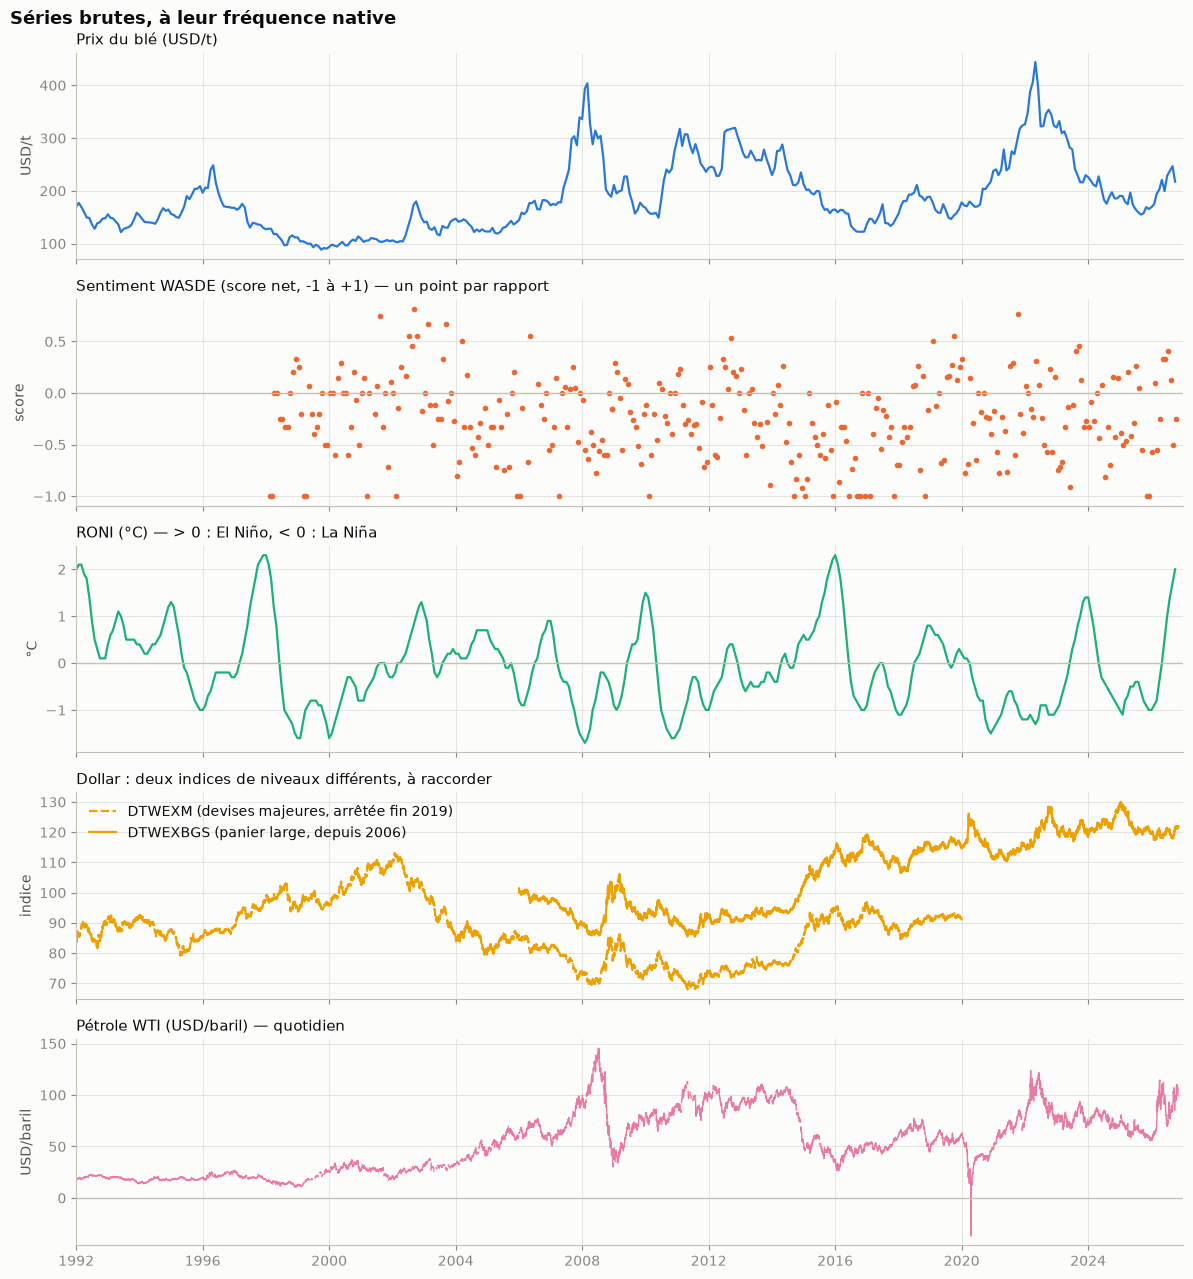

In [5]:
fig, axes = plt.subplots(5, 1, figsize=(12, 13), sharex=True)
xlim = (pd.Timestamp(START), pd.Timestamp("2026-12-31"))

ax = axes[0]
ax.plot(wheat_raw["date"], wheat_raw["wheat_price_usd"], color=COLORS["wheat_price_usd"])
ax.set_title(LABELS["wheat_price_usd"]); ax.set_ylabel("USD/t")

ax = axes[1]
w = RAW["wasde_sentiment"].dropna()
ax.plot(w["date"], w["wasde_sentiment"], "o", ms=3, color=COLORS["wasde_sentiment"])
ax.axhline(0, color="#c3c2b7", lw=1)
ax.set_title(LABELS["wasde_sentiment"] + " — un point par rapport"); ax.set_ylabel("score")

ax = axes[2]
ax.plot(roni_raw["date"], roni_raw["roni_index"], color=COLORS["roni_index"])
ax.axhline(0, color="#c3c2b7", lw=1)
ax.set_title(LABELS["roni_index"] + " — > 0 : El Niño, < 0 : La Niña"); ax.set_ylabel("°C")

ax = axes[3]
ax.plot(dxy_history_raw["date"], dxy_history_raw["dxy_history"], color=COLORS["dxy_index"], ls="--", label="DTWEXM (devises majeures, arrêtée fin 2019)")
ax.plot(dxy_current_raw["date"], dxy_current_raw["dxy_current"], color=COLORS["dxy_index"], label="DTWEXBGS (panier large, depuis 2006)")
ax.set_title("Dollar : deux indices de niveaux différents, à raccorder"); ax.set_ylabel("indice")
ax.legend(loc="upper left")

ax = axes[4]
ax.plot(wti_raw["date"], wti_raw["wti_price_usd"], color=COLORS["wti_price_usd"], lw=1)
ax.axhline(0, color="#c3c2b7", lw=1)
ax.set_title(LABELS["wti_price_usd"] + " — quotidien"); ax.set_ylabel("USD/baril")

axes[-1].set_xlim(xlim)
axes[-1].xaxis.set_major_locator(mdates.YearLocator(4))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.suptitle("Séries brutes, à leur fréquence native", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

In [6]:
# ---- Contrôles spécifiques par source ----
print("=== WTI : valeurs <= 0 ===")
print(wti_raw.loc[wti_raw["wti_price_usd"] <= 0].to_string(index=False))

print("\n=== FRED : jours sans cotation ('.' dans l'API), ignorés ===")
for name, frame, col in [("dollar historique", dxy_history_raw, "dxy_history"),
                         ("dollar courant", dxy_current_raw, "dxy_current"), ("WTI", wti_raw, "wti_price_usd")]:
    print(f"{name:18s} {int(frame[col].isna().sum()):4d} jours manquants sur {len(frame)}")

print("\n=== RONI : saisons pas encore publiées ===")
print(roni_raw.loc[roni_raw["roni_index"].isna(), "date"].dt.strftime("%Y-%m").tolist())

reports = wasde_reports[~wasde_reports["partial_errata"]]
print("\n=== WASDE ===")
print(f"Fichiers : {len(wasde_reports)} dont {int(wasde_reports['partial_errata'].sum())} erratas partiels exclus")
print("Source de la date :", reports["date_source"].value_counts().to_dict())
print(f"Rapports sans narratif blé (PDF scannés / bloc 'WHEAT:' absent) : {int(reports['wasde_sentiment'].isna().sum())}")
print("  par année :", reports.loc[reports["wasde_sentiment"].isna(), "date"].dt.year.value_counts().sort_index().to_dict())
scored = reports.dropna(subset=["wasde_sentiment"])
print(f"Rapports sans aucun mot du lexique (score = 0 par construction) : {int((scored['bull_words'] + scored['bear_words'] == 0).sum())} sur {len(scored)}")
print("Jour du mois des rapports datés par l'en-tête PDF (doit se concentrer autour du 8-12) :")
print(reports.loc[reports["date_source"] == "en-tête PDF", "date"].dt.day.value_counts().sort_index().to_dict())

=== WTI : valeurs <= 0 ===
      date  wti_price_usd
2020-04-20         -36.98

=== FRED : jours sans cotation ('.' dans l'API), ignorés ===
dollar historique   211 jours manquants sur 7305
dollar courant      213 jours manquants sur 5440
WTI                1022 jours manquants sur 9090

=== RONI : saisons pas encore publiées ===
['2026-11', '2026-12', '2027-01']

=== WASDE ===
Fichiers : 382 dont 9 erratas partiels exclus
Source de la date : {'en-tête PDF': 329, 'nom de fichier': 44}
Rapports sans narratif blé (PDF scannés / bloc 'WHEAT:' absent) : 37
  par année : {1992: 12, 1993: 12, 1994: 12, 2008: 1}
Rapports sans aucun mot du lexique (score = 0 par construction) : 7 sur 336
Jour du mois des rapports datés par l'en-tête PDF (doit se concentrer autour du 8-12) :
{8: 26, 9: 54, 10: 80, 11: 61, 12: 105, 14: 2, 28: 1}


## 3. Mise à fréquence mensuelle, raccord du dollar, centrage

Règles appliquées :
- **moyenne mensuelle** de toutes les observations d'un mois (une seule observation : inchangée) ;
- pour les séries quotidiennes, le **dernier mois est écarté s'il est en cours** (peu de jours cotés) ; les trous internes de la source sont conservés (moyenne des jours disponibles) mais signalés ;
- le dollar est reconstitué en **chaînant** DTWEXM sur DTWEXBGS au premier mois commun (janvier 2006) : leur rapport n'étant pas constant, une échelle unique créerait un saut artificiel ;
- échantillon commun = mois où les 5 variables sont observées ; puis **centrage-réduction** (moyenne 0, écart-type 1) sur cet échantillon.

In [7]:
DAILY = ["dxy_history", "dxy_current", "wti_price_usd"]
monthly, counts = {}, {}
for name, frame in RAW.items():
    s = frame.set_index("date")[name].dropna().sort_index()
    grouped = s.groupby(s.index.to_period("M").to_timestamp())
    monthly[name], counts[name] = grouped.mean(), grouped.size()
    if name in DAILY:
        # Seul le dernier mois est écarté s'il est en cours (peu de jours cotés)
        last = counts[name].index[-1]
        if counts[name].iloc[-1] < 0.7 * counts[name].median():
            print(f"{name}: mois en cours {last:%Y-%m} ({counts[name].iloc[-1]} jours) mis à NaN")
            monthly[name] = monthly[name].mask(monthly[name].index == last)
        # Les trous internes de la source sont conservés (moyenne des jours disponibles) mais signalés
        sparse = counts[name][(counts[name] < 15) & (counts[name].index < last)]
        print(f"{name}: {len(sparse)} mois avec moins de 15 jours cotés (moyenne conservée)"
              + (f", entre {sparse.index.min():%Y-%m} et {sparse.index.max():%Y-%m}" if len(sparse) else ""))

# ---- Raccord du dollar ----
# Les deux indices ont des niveaux différents et leur rapport n'est pas constant : une échelle unique
# créerait un saut artificiel à la jonction. On "chaîne" donc l'historique sur l'indice courant au
# premier mois commun, de sorte que la variation mensuelle à la jonction est celle de l'historique.
overlap = pd.concat([monthly["dxy_history"], monthly["dxy_current"]], axis=1).dropna()
junction = overlap.index[0]
scale = overlap.loc[junction, "dxy_current"] / overlap.loc[junction, "dxy_history"]
ratio = overlap["dxy_current"] / overlap["dxy_history"]
print(f"\nRaccord dollar : {len(overlap)} mois de recouvrement ({overlap.index.min():%Y-%m} -> {overlap.index.max():%Y-%m})")
print(f"  rapport courant/historique : {scale:.3f} à la jonction ; sur le recouvrement : médiane {ratio.median():.3f}, "
      f"5e-95e pct [{ratio.quantile(.05):.3f}, {ratio.quantile(.95):.3f}] (non constant)")
print(f"  corrélation des niveaux : {overlap['dxy_current'].corr(overlap['dxy_history']):.3f} ; "
      f"corrélation des variations mensuelles (log) : {np.log(overlap).diff().corr().iloc[0, 1]:.3f}")
dxy_index = monthly["dxy_current"].combine_first(monthly["dxy_history"] * scale)

monthly_all = pd.concat({
    "wheat_price_usd": monthly["wheat_price_usd"],
    "wasde_sentiment": monthly["wasde_sentiment"],
    "roni_index": monthly["roni_index"],
    "dxy_index": dxy_index,
    "wti_price_usd": monthly["wti_price_usd"],
}, axis=1)
monthly_all = monthly_all.reindex(pd.date_range(monthly_all.index.min(), monthly_all.index.max(), freq="MS"))
monthly_all.index.name = "date"

coverage = pd.DataFrame({
    "premier_mois": monthly_all.apply(lambda s: s.first_valid_index().strftime("%Y-%m")),
    "dernier_mois": monthly_all.apply(lambda s: s.last_valid_index().strftime("%Y-%m")),
    "n_mois": monthly_all.notna().sum(),
    "trous_internes": monthly_all.apply(lambda s: int(s.loc[s.first_valid_index():s.last_valid_index()].isna().sum())),
})
display(coverage)

dxy_history: 0 mois avec moins de 15 jours cotés (moyenne conservée)
dxy_current: mois en cours 2026-11 (5 jours) mis à NaN
dxy_current: 0 mois avec moins de 15 jours cotés (moyenne conservée)
wti_price_usd: mois en cours 2026-11 (2 jours) mis à NaN
wti_price_usd: 35 mois avec moins de 15 jours cotés (moyenne conservée), entre 1994-04 et 2015-01

Raccord dollar : 168 mois de recouvrement (2006-01 -> 2019-12)
  rapport courant/historique : 1.183 à la jonction ; sur le recouvrement : médiane 1.233, 5e-95e pct [1.185, 1.264] (non constant)
  corrélation des niveaux : 0.978 ; corrélation des variations mensuelles (log) : 0.927


,premier_mois,dernier_mois,n_mois,trous_internes
wheat_price_usd,1992-01,2026-10,418,0
wasde_sentiment,1998-02,2026-10,335,10
roni_index,1992-01,2026-10,418,0
dxy_index,1992-01,2026-10,418,0
wti_price_usd,1992-01,2026-10,418,0


In [8]:
# ---- Échantillon commun ----
panel = monthly_all.dropna()
span = pd.date_range(panel.index.min(), panel.index.max(), freq="MS")
holes = span.difference(panel.index)
print(f"Échantillon commun : {len(panel)} mois, {panel.index.min():%Y-%m} -> {panel.index.max():%Y-%m}")
print(f"Mois manquants à l'intérieur de la période ({len(holes)}) :")
for d in holes:
    missing = [SHORT[c] for c in monthly_all.columns if pd.isna(monthly_all.loc[d, c])]
    print(f"  {d:%Y-%m} : {', '.join(missing)}")

# ---- Centrage-réduction ----
panel_z = (panel - panel.mean()) / panel.std()
display(pd.DataFrame({"moyenne (brut)": panel.mean(), "écart-type (brut)": panel.std(),
                      "moyenne (centré)": panel_z.mean(), "écart-type (centré)": panel_z.std()}).round(3))

Échantillon commun : 335 mois, 1998-02 -> 2026-10
Mois manquants à l'intérieur de la période (10) :
  2001-05 : Sentiment
  2002-05 : Sentiment
  2002-11 : Sentiment
  2004-11 : Sentiment
  2006-03 : Sentiment
  2006-06 : Sentiment
  2006-07 : Sentiment
  2013-10 : Sentiment
  2019-01 : Sentiment
  2025-10 : Sentiment


,moyenne (brut),écart-type (brut),moyenne (centré),écart-type (centré)
wheat_price_usd,193.516,72.061,-0.0,1.0
wasde_sentiment,-0.244,0.396,0.0,1.0
roni_index,-0.221,0.817,0.0,1.0
dxy_index,108.723,12.306,-0.0,1.0
wti_price_usd,61.466,26.964,0.0,1.0


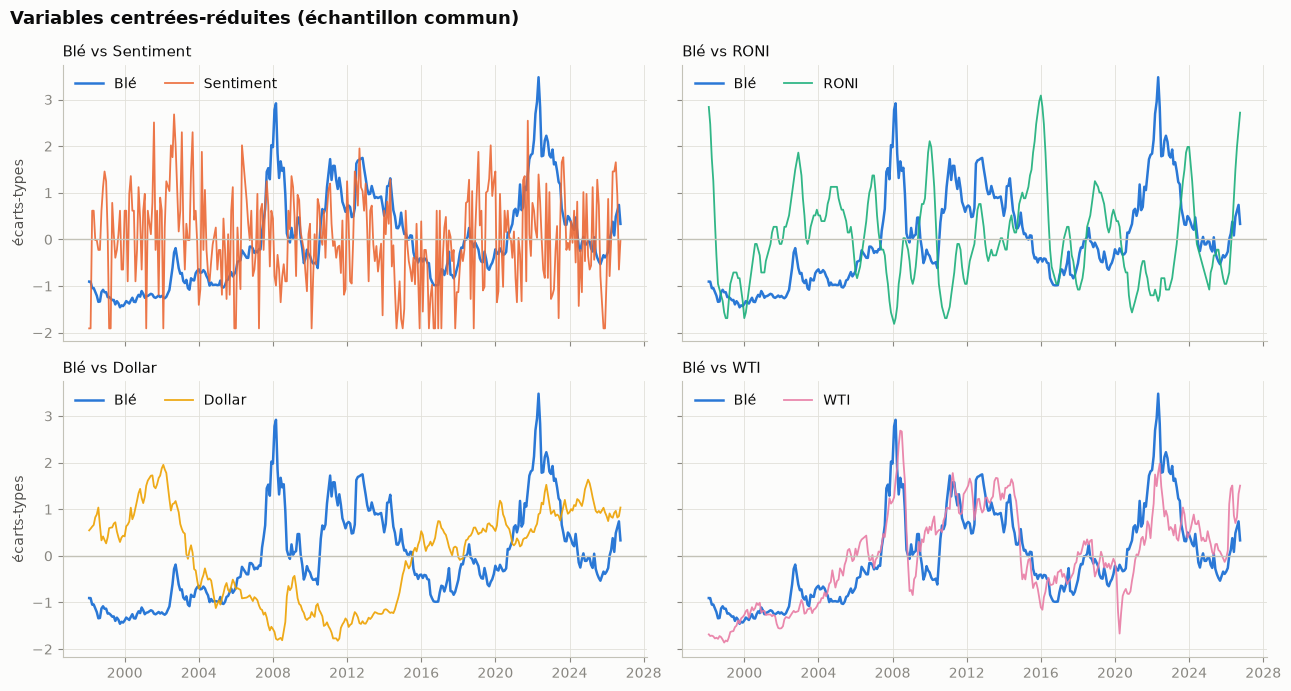

In [9]:
# Variables centrées-réduites : même unité, donc comparables sur un même axe. Blé (bleu) contre chaque variable.
fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True, sharey=True)
for ax, col in zip(axes.ravel(), ["wasde_sentiment", "roni_index", "dxy_index", "wti_price_usd"]):
    ax.plot(panel_z.index, panel_z["wheat_price_usd"], color=COLORS["wheat_price_usd"], label=SHORT["wheat_price_usd"], lw=1.8)
    ax.plot(panel_z.index, panel_z[col], color=COLORS[col], label=SHORT[col], lw=1.3, alpha=0.9)
    ax.axhline(0, color="#c3c2b7", lw=1)
    ax.set_title(f"Blé vs {SHORT[col]}")
    ax.legend(loc="upper left", ncol=2)
for ax in axes[1]:
    ax.set_xlabel("")
for ax in axes[:, 0]:
    ax.set_ylabel("écarts-types")
fig.suptitle("Variables centrées-réduites (échantillon commun)", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

In [10]:
# ---- Valeurs extrêmes (sur les variations mensuelles) : réelles ou erreurs ? ----
# Prix en log-différences (variations relatives), RONI et sentiment en différences.
TRANSFORM = {"wheat_price_usd": "dlog", "wti_price_usd": "dlog", "dxy_index": "dlog",
             "wasde_sentiment": "level", "roni_index": "level"}

variation = pd.DataFrame({
    c: (np.log(monthly_all[c]).diff() if TRANSFORM[c] == "dlog" else monthly_all[c].diff())
    for c in monthly_all.columns
})
robust_z = 0.6745 * (variation - variation.median()) / (variation - variation.median()).abs().median()
extremes = (robust_z.stack().rename("z_robuste").to_frame()
            .join(variation.stack().rename("variation")))
extremes = extremes[extremes["z_robuste"].abs() > 4].sort_values("z_robuste", key=abs, ascending=False)
print("Variations mensuelles à plus de 4 écarts absolus médians (z robuste, base MAD) :")
display(extremes.head(15).round(3))
print("\nNombre par variable :", extremes.reset_index()["level_1"].value_counts().to_dict())

Variations mensuelles à plus de 4 écarts absolus médians (z robuste, base MAD) :


,,z_robuste,variation
date,,,
2020-04-01,wti_price_usd,-7.510,-0.568
2020-03-01,wti_price_usd,-7.254,-0.548
2020-05-01,wti_price_usd,6.886,0.546
2008-10-01,dxy_index,5.081,0.072
1998-06-01,roni_index,-4.721,-0.700
2008-12-01,wti_price_usd,-4.457,-0.332
2008-10-01,wheat_price_usd,-4.386,-0.260
2026-03-01,wti_price_usd,4.333,0.348
2012-07-01,wheat_price_usd,4.282,0.250



Nombre par variable : {'roni_index': 7, 'wti_price_usd': 6, 'wheat_price_usd': 2, 'dxy_index': 1}


## 4. Corrélations

### 4.1 Corrélations en niveaux
Les corrélations ci-dessous portent sur les niveaux centrés-réduits (la corrélation est invariante au centrage-réduction). **Attention** : deux séries qui dérivent dans le temps sont souvent corrélées sans lien réel (corrélation « fallacieuse »). La section 4.2 vérifie la stationnarité avant d'interpréter.

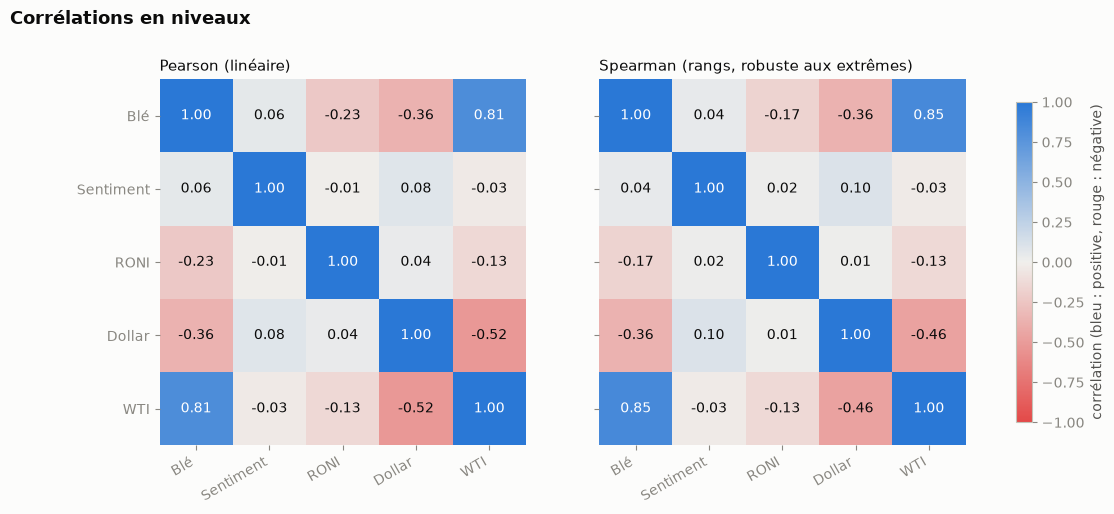

In [11]:
DIVERGING = LinearSegmentedColormap.from_list("blue_red", ["#e34948", "#f0efec", "#2a78d6"])  # rouge - / gris 0 / bleu +

def heatmap(ax, corr, title, labels, show_y=True):
    names = [labels[c] for c in corr.columns]
    im = ax.imshow(corr.values, cmap=DIVERGING, vmin=-1, vmax=1)
    ax.set_xticks(range(len(names)), names, rotation=30, ha="right")
    ax.set_yticks(range(len(names)), names if show_y else [])
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    for i in range(len(names)):
        for j in range(len(names)):
            v = corr.values[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", color="#ffffff" if abs(v) > 0.6 else INK)
    ax.set_title(title)
    return im

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
heatmap(axes[0], panel_z.corr(), "Pearson (linéaire)", SHORT)
im = heatmap(axes[1], panel_z.corr(method="spearman"), "Spearman (rangs, robuste aux extrêmes)", SHORT, show_y=False)
fig.colorbar(im, ax=axes, shrink=0.8, label="corrélation (bleu : positive, rouge : négative)")
fig.suptitle("Corrélations en niveaux", x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.show()

### 4.2 Corrélations des variations mensuelles

Les prix (blé, dollar, WTI) sont passés en variations relatives (Δlog) pour éviter les corrélations fallacieuses entre séries qui dérivent ; le RONI et le sentiment, qui oscillent autour d'une moyenne, restent en niveau.


Échantillon des variations : 335 mois (1998-02 -> 2026-10)


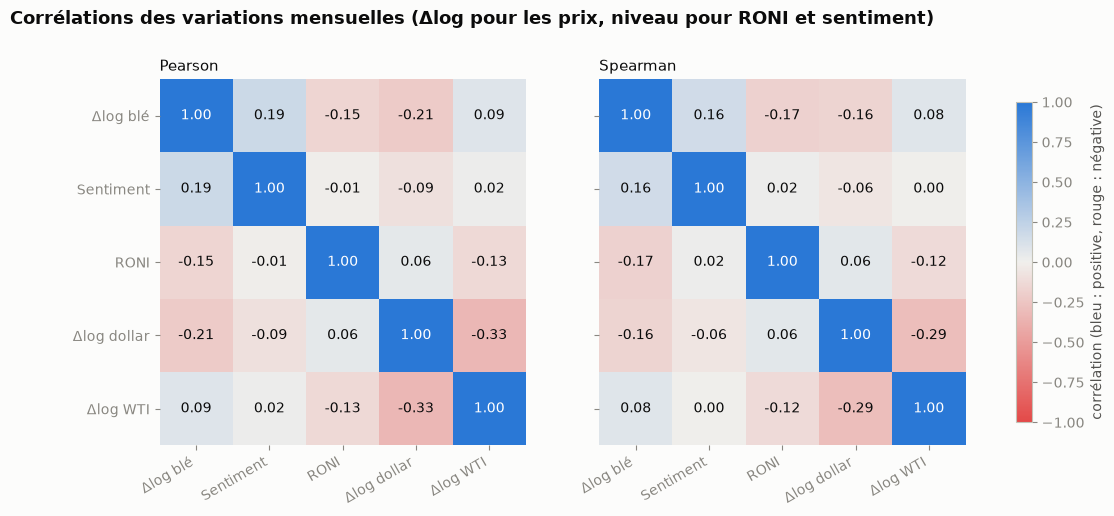

Seuil de significativité approximatif à 5 % : |r| > 0.107 (n = 335)


In [12]:
# Panel de variations : Δlog pour les séries non stationnaires, niveau pour les stationnaires
changes = pd.DataFrame({
    c: (np.log(monthly_all[c]).diff() if TRANSFORM[c] == "dlog" else monthly_all[c])
    for c in monthly_all.columns
})
CHG = {"wheat_price_usd": "Δlog blé", "wti_price_usd": "Δlog WTI", "dxy_index": "Δlog dollar",
       "wasde_sentiment": "Sentiment", "roni_index": "RONI"}
changes_ok = changes.dropna()
print(f"\nÉchantillon des variations : {len(changes_ok)} mois ({changes_ok.index.min():%Y-%m} -> {changes_ok.index.max():%Y-%m})")

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
heatmap(axes[0], changes_ok.corr(), "Pearson", CHG)
im = heatmap(axes[1], changes_ok.corr(method="spearman"), "Spearman", CHG, show_y=False)
fig.colorbar(im, ax=axes, shrink=0.8, label="corrélation (bleu : positive, rouge : négative)")
fig.suptitle("Corrélations des variations mensuelles (Δlog pour les prix, niveau pour RONI et sentiment)", x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.show()

n = len(changes_ok)
print(f"Seuil de significativité approximatif à 5 % : |r| > {1.96 / np.sqrt(n):.3f} (n = {n})")

### 4.3 Corrélations décalées : qui précède le blé ?

Corrélation entre la variation du blé au mois *t* et chaque variable au mois *t − k*. Pour k > 0, la variable **précède** le blé (utile pour prévoir) ; pour k < 0, c'est le blé qui précède. Les barres colorées dépassent le seuil de significativité à 5 % (bande grisée).

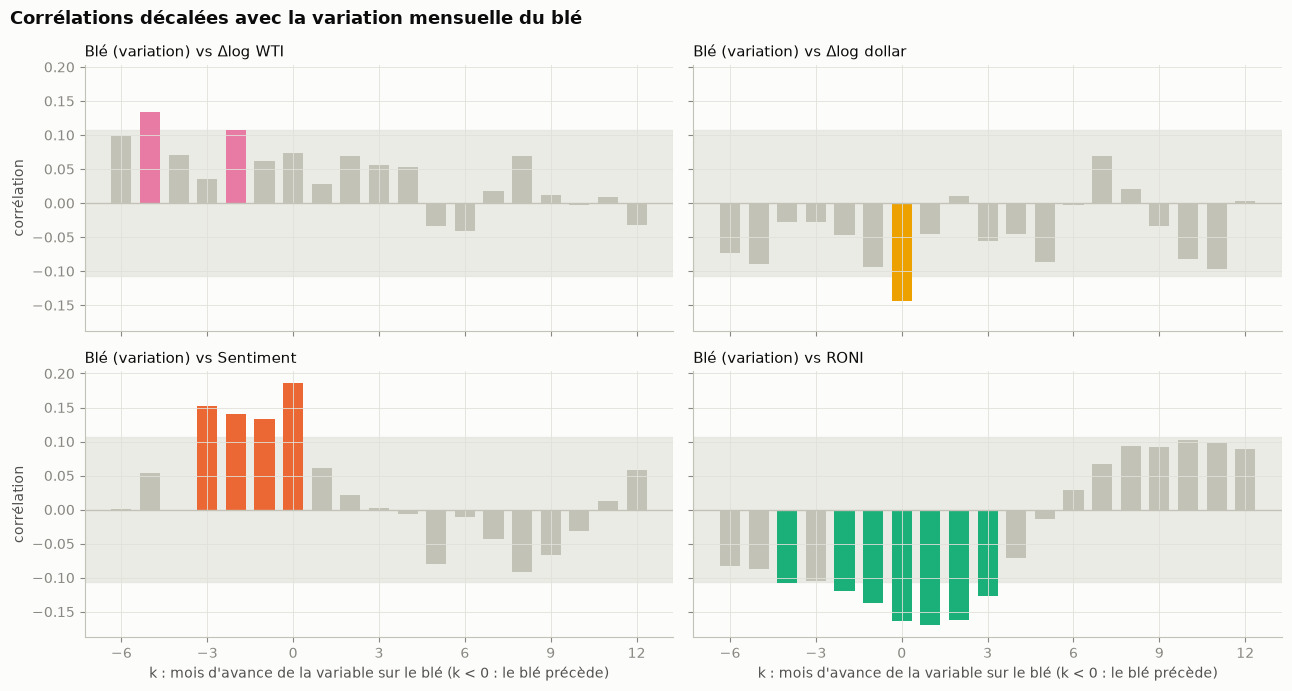

,corr à k=0,meilleur k,corr au meilleur k,seuil 5 %
wti_price_usd,0.073,-5,0.134,0.107
dxy_index,-0.144,0,-0.144,0.107
wasde_sentiment,0.186,0,0.186,0.107
roni_index,-0.164,1,-0.170,0.107


In [13]:
EXPLANATORY = ["wti_price_usd", "dxy_index", "wasde_sentiment", "roni_index"]
LAGS = list(range(-6, 13))
band = 1.96 / np.sqrt(len(changes_ok))

lag_corr = pd.DataFrame({c: [changes["wheat_price_usd"].corr(changes[c].shift(k)) for k in LAGS]
                         for c in EXPLANATORY}, index=pd.Index(LAGS, name="k"))

fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharey=True, sharex=True)
for ax, c in zip(axes.ravel(), EXPLANATORY):
    vals = lag_corr[c]
    ax.axhspan(-band, band, color=GRID, alpha=0.6, zorder=0)
    ax.bar(LAGS, vals, width=0.7, color=[COLORS[c] if abs(v) > band else "#c3c2b7" for v in vals])
    ax.axhline(0, color="#c3c2b7", lw=1)
    ax.set_title(f"Blé (variation) vs {CHG[c]}")
    ax.set_xticks(range(-6, 13, 3))
for ax in axes[1]:
    ax.set_xlabel("k : mois d'avance de la variable sur le blé (k < 0 : le blé précède)")
for ax in axes[:, 0]:
    ax.set_ylabel("corrélation")
fig.suptitle("Corrélations décalées avec la variation mensuelle du blé", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

best = pd.DataFrame({
    "corr à k=0": lag_corr.loc[0],
    "meilleur k": lag_corr.abs().idxmax(),
    "corr au meilleur k": [lag_corr.loc[lag_corr[c].abs().idxmax(), c] for c in lag_corr.columns],
}).round(3)
best["seuil 5 %"] = round(band, 3)
display(best)

### 4.4 Stabilité dans le temps : corrélation glissante sur 60 mois

Une corrélation moyenne peut cacher des changements de régime (par exemple la hausse de 2007-2008 ou la crise ukrainienne de 2022).

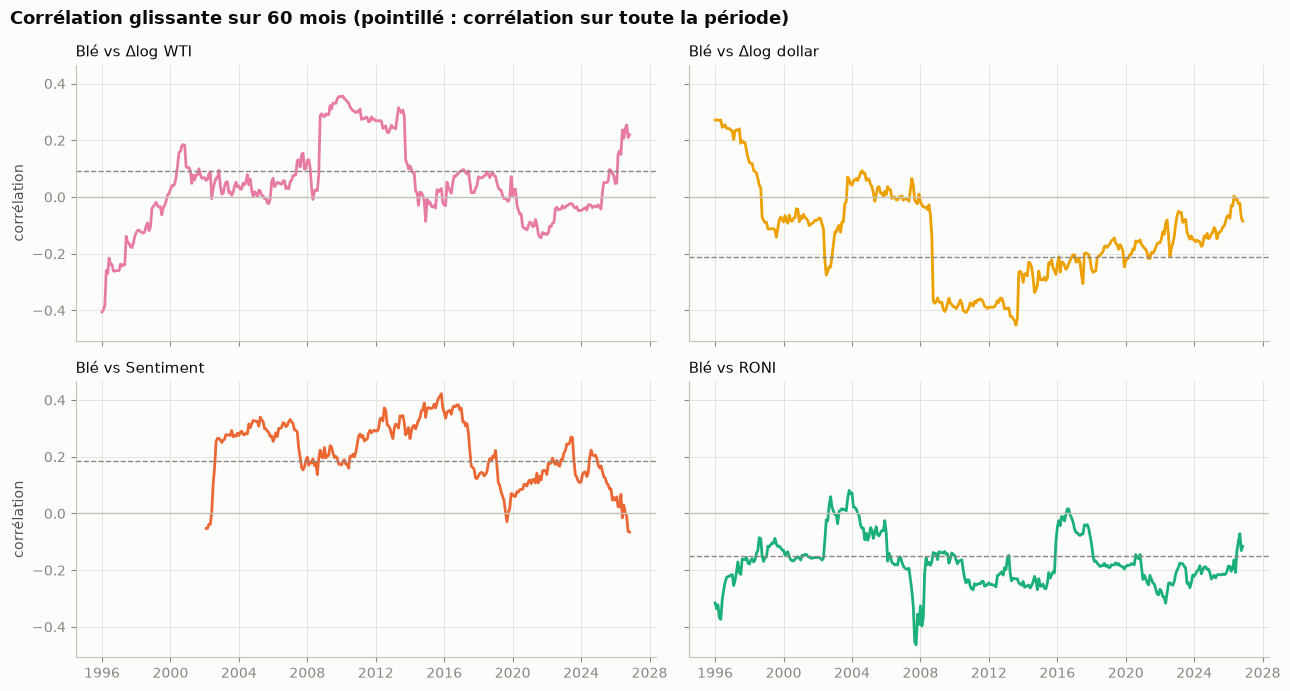

In [14]:
WINDOW = 60
fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharey=True, sharex=True)
for ax, c in zip(axes.ravel(), EXPLANATORY):
    rolling = changes["wheat_price_usd"].rolling(WINDOW, min_periods=48).corr(changes[c])
    ax.plot(rolling.index, rolling, color=COLORS[c], lw=2)
    ax.axhline(0, color="#c3c2b7", lw=1)
    ax.axhline(changes_ok.corr().loc["wheat_price_usd", c], color=MUTED, lw=1, ls="--")
    ax.set_title(f"Blé vs {CHG[c]}")
for ax in axes[:, 0]:
    ax.set_ylabel("corrélation")
fig.suptitle(f"Corrélation glissante sur {WINDOW} mois (pointillé : corrélation sur toute la période)",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

## 5. Régression linéaire en niveaux avec décalages choisis par corrélation

**Modèle** (variables centrées-réduites, coefficients standardisés) :

Blé(t) = a + b₁·WTI(t − k₁) + b₂·Dollar(t − k₂) + b₃·Sentiment(t − k₃) + b₄·RONI(t − k₄) + ε(t)

Pour chaque variable, le décalage k est celui qui **maximise la corrélation absolue** avec la variation du blé dans le graphique 4.3, en ne retenant que les décalages k ≥ 0 (la variable précède le blé : seuls ceux-là sont utilisables pour prévoir). On régresse ensuite les **niveaux**.

⚠️ Ce R² élevé est à prendre avec précaution : le blé, le dollar et le WTI dérivent dans le temps, ce qui gonfle mécaniquement le R² en niveaux (régression fallacieuse possible). Le Durbin-Watson et les t-stats Newey-West (corrigés de l'autocorrélation, 12 retards) permettent de le mesurer.

In [15]:
import statsmodels.api as sm
from statsmodels.stats.stattools import durbin_watson

TARGET = "wheat_price_usd"

# Décalage retenu par variable : k >= 0 qui maximise |corrélation| dans le graphique 4.3
selected_lags = {c: int(lag_corr.loc[lag_corr.index >= 0, c].abs().idxmax()) for c in EXPLANATORY}
display(pd.DataFrame({"décalage k (mois)": selected_lags,
                      "corrélation (variations) à ce k": {c: lag_corr.loc[k, c] for c, k in selected_lags.items()}}).round(3))


def fit_levels(lags):
    X = pd.DataFrame({c: monthly_all[c].shift(k) for c, k in lags.items()})
    data = pd.concat([monthly_all[TARGET], X], axis=1).dropna()
    z = (data - data.mean()) / data.std()
    Xc = sm.add_constant(z[list(lags)])
    ols = sm.OLS(z[TARGET], Xc).fit()
    hac = sm.OLS(z[TARGET], Xc).fit(cov_type="HAC", cov_kwds={"maxlags": 12})
    return z, ols, hac


z_best, ols_best, hac_best = fit_levels(selected_lags)
_, ols_nolag, _ = fit_levels({c: 0 for c in EXPLANATORY})

comparison = pd.DataFrame({
    name: {"n": int(m.nobs), "R²": m.rsquared, "R² ajusté": m.rsquared_adj, "AIC": m.aic,
           "Durbin-Watson": durbin_watson(m.resid)}
    for name, m in {"sans décalage (k = 0 partout)": ols_nolag, "décalages retenus": ols_best}.items()
}).T
display(comparison.round(3))

summary = pd.DataFrame({
    "coef": ols_best.params, "t (MCO)": ols_best.tvalues,
    "t (Newey-West)": hac_best.tvalues, "p (NW)": hac_best.pvalues,
}).rename(index={c: f"{CHG[c]}(t-{k})".replace("Δlog ", "") for c, k in selected_lags.items()})
display(summary.round(3))

,décalage k (mois),corrélation (variations) à ce k
wti_price_usd,0,0.073
dxy_index,0,-0.144
wasde_sentiment,0,0.186
roni_index,1,-0.170


,n,R²,R² ajusté,AIC,Durbin-Watson
sans décalage (k = 0 partout),335.0,0.688,0.685,568.959,0.248
décalages retenus,335.0,0.688,0.684,569.968,0.244


,coef,t (MCO),t (Newey-West),p (NW)
const,-0.000,-0.000,-0.000,1.000
WTI(t-0),0.829,22.583,7.361,0.000
dollar(t-0),0.066,1.822,0.548,0.584
Sentiment(t-0),0.077,2.483,1.791,0.073
RONI(t-1),-0.117,-3.713,-1.443,0.149


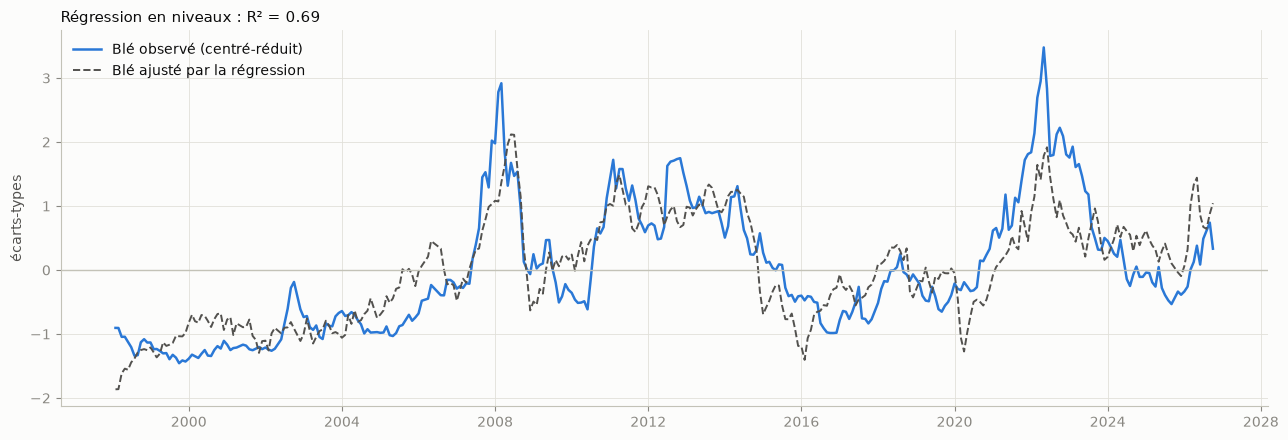

In [16]:
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(z_best.index, z_best[TARGET], color=COLORS["wheat_price_usd"], label="Blé observé (centré-réduit)", lw=1.8)
ax.plot(z_best.index, ols_best.fittedvalues, color=INK2, ls="--", label="Blé ajusté par la régression", lw=1.4)
ax.axhline(0, color="#c3c2b7", lw=1)
ax.set_title(f"Régression en niveaux : R² = {ols_best.rsquared:.2f}")
ax.set_ylabel("écarts-types")
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

### 5.1 Toutes les combinaisons de décalages (k de 0 à 3 pour chaque variable)

4 variables × 4 décalages = 256 régressions, estimées sur **le même échantillon** (mois où tous les décalages 0 à 3 sont disponibles) pour que R² ajusté et AIC soient comparables. Classement par AIC.

In [17]:
from itertools import product

GRID = range(0, 4)
cols = {(c, k): monthly_all[c].shift(k) for c in EXPLANATORY for k in GRID}
grid_data = pd.concat([monthly_all[TARGET], pd.DataFrame({f"{c}|{k}": v for (c, k), v in cols.items()})], axis=1).dropna()
grid_z = (grid_data - grid_data.mean()) / grid_data.std()
print(f"Échantillon commun : {len(grid_z)} mois ({grid_z.index.min():%Y-%m} -> {grid_z.index.max():%Y-%m})")

rows = []
for ks in product(GRID, repeat=len(EXPLANATORY)):
    names = [f"{c}|{k}" for c, k in zip(EXPLANATORY, ks)]
    m = sm.OLS(grid_z[TARGET], sm.add_constant(grid_z[names])).fit()
    rows.append({**{f"k {SHORT[c]}": k for c, k in zip(EXPLANATORY, ks)},
                 "R²": m.rsquared, "R² ajusté": m.rsquared_adj, "AIC": m.aic, "Durbin-Watson": durbin_watson(m.resid)})
grid_results = pd.DataFrame(rows).sort_values("AIC").reset_index(drop=True)
print(f"{len(grid_results)} combinaisons ; R² ajusté de {grid_results['R² ajusté'].min():.3f} à {grid_results['R² ajusté'].max():.3f}")
display(grid_results.head(10).round(3))

best = grid_results.iloc[0]
best_lags = {c: int(best[f"k {SHORT[c]}"]) for c in EXPLANATORY}
names = [f"{c}|{k}" for c, k in best_lags.items()]
X = sm.add_constant(grid_z[names])
ols_g = sm.OLS(grid_z[TARGET], X).fit()
hac_g = sm.OLS(grid_z[TARGET], X).fit(cov_type="HAC", cov_kwds={"maxlags": 12})
print(f"Meilleure combinaison (AIC) : {best_lags}")
display(pd.DataFrame({"coef": ols_g.params, "t (MCO)": ols_g.tvalues, "t (Newey-West)": hac_g.tvalues, "p (NW)": hac_g.pvalues})
        .rename(index={f"{c}|{k}": f"{SHORT[c]}(t-{k})" for c, k in best_lags.items()}).round(3))

Échantillon commun : 306 mois (1998-05 -> 2026-10)


256 combinaisons ; R² ajusté de 0.640 à 0.686


,k WTI,k Dollar,k Sentiment,k RONI,R²,R² ajusté,AIC,Durbin-Watson
0,0,2,0,0,0.690,0.686,518.803,0.277
1,0,1,0,0,0.690,0.686,518.818,0.277
2,0,2,0,1,0.690,0.686,519.030,0.272
3,0,1,0,1,0.690,0.686,519.033,0.271
4,0,3,0,0,0.690,0.686,519.054,0.278
5,0,0,0,0,0.690,0.686,519.216,0.277
6,0,3,0,1,0.690,0.686,519.274,0.272
7,0,0,0,1,0.690,0.685,519.400,0.271
8,0,2,0,2,0.689,0.685,519.612,0.265
9,0,1,0,2,0.689,0.685,519.623,0.265


Meilleure combinaison (AIC) : {'wti_price_usd': 0, 'dxy_index': 2, 'wasde_sentiment': 0, 'roni_index': 0}


,coef,t (MCO),t (Newey-West),p (NW)
const,-0.000,-0.000,-0.000,1.000
WTI(t-0),0.838,22.418,7.247,0.000
Dollar(t-2),0.070,1.870,0.568,0.570
Sentiment(t-0),0.086,2.678,1.873,0.061
RONI(t-0),-0.135,-4.178,-1.558,0.119


## 6. Séparation chronologique entraînement / test (70 % / 30 %)

On coupe l'échantillon **dans l'ordre du temps** (pas de mélange aléatoire) : les 70 % premiers mois servent à estimer le modèle, les 30 % derniers à l'évaluer sur des données jamais vues. Pour éviter toute fuite d'information du futur :
- la moyenne et l'écart-type du centrage-réduction sont calculés **sur l'entraînement seulement** ;
- les décalages (k de 0 à 3 pour chaque variable, 256 combinaisons) sont choisis **sur l'entraînement** (AIC), puis figés.

Deux modèles sont comparés : **niveaux** (blé en niveau, comme en section 5) et **variations** (Δlog du blé). Le **R² test** est calculé par rapport à la moyenne de l'entraînement (R² hors échantillon : positif = mieux que de prédire la moyenne passée). Références : pour les niveaux, le prix du mois précédent (persistance) ; pour les variations, une variation nulle (marche aléatoire).

In [18]:
SPLIT = 0.7
GRID = range(0, 4)
chg_data = pd.concat([changes[TARGET], pd.DataFrame({f"{c}|{k}": changes[c].shift(k) for c in EXPLANATORY for k in GRID})],
                     axis=1).dropna()


def chrono_split_eval(data, kind):
    n_train = int(len(data) * SPLIT)
    mu, sd = data.iloc[:n_train].mean(), data.iloc[:n_train].std()   # statistiques de l'entraînement uniquement
    z = (data - mu) / sd
    z_tr, z_te = z.iloc[:n_train], z.iloc[n_train:]

    best = None
    for ks in product(GRID, repeat=len(EXPLANATORY)):               # choix des décalages sur l'entraînement
        names = [f"{c}|{k}" for c, k in zip(EXPLANATORY, ks)]
        m = sm.OLS(z_tr[TARGET], sm.add_constant(z_tr[names])).fit()
        if best is None or m.aic < best[0]:
            best = (m.aic, ks, names, m)
    _, ks, names, m = best
    hac = sm.OLS(z_tr[TARGET], sm.add_constant(z_tr[names])).fit(cov_type="HAC", cov_kwds={"maxlags": 12})
    pred = m.predict(sm.add_constant(z_te[names], has_constant="add"))
    y = z_te[TARGET]

    sse = ((y - pred) ** 2).sum()
    r2_test = 1 - sse / ((y - z_tr[TARGET].mean()) ** 2).sum()
    naive = z[TARGET].shift(1).iloc[n_train:] if kind == "niveaux" else pd.Series((0 - mu[TARGET]) / sd[TARGET], index=y.index)
    out = {
        "entraînement": f"{z_tr.index.min():%Y-%m} -> {z_tr.index.max():%Y-%m} ({len(z_tr)})",
        "test": f"{z_te.index.min():%Y-%m} -> {z_te.index.max():%Y-%m} ({len(z_te)})",
        "décalages k (WTI, dollar, sentiment, RONI)": str(ks),
        "R² entraînement": m.rsquared,
        "R² test": r2_test,
        "RMSE test modèle": np.sqrt(((y - pred) ** 2).mean()),
        "RMSE test référence": np.sqrt(((y - naive) ** 2).mean()),
    }
    if kind == "variations":
        raw_pred, raw_y = pred * sd[TARGET] + mu[TARGET], data[TARGET].iloc[n_train:]
        out["taux de bon signe (test)"] = float((np.sign(raw_pred) == np.sign(raw_y)).mean())
    coefs = pd.DataFrame({"coef": m.params, "t (MCO)": m.tvalues, "t (Newey-West)": hac.tvalues}).rename(
        index={f"{c}|{k}": f"{SHORT[c]}(t-{k})" for c, k in zip(EXPLANATORY, ks)})
    return out, coefs, y, pred


res_lvl, coef_lvl, y_lvl, pred_lvl = chrono_split_eval(grid_data, "niveaux")
res_chg, coef_chg, y_chg, pred_chg = chrono_split_eval(chg_data, "variations")
display(pd.DataFrame({"niveaux": res_lvl, "variations (Δlog blé)": res_chg}).astype(str).replace("nan", "—"))
print("Coefficients estimés sur l'entraînement (variables centrées-réduites)")
print("--- niveaux"); display(coef_lvl.round(3))
print("--- variations"); display(coef_chg.round(3))

,niveaux,variations (Δlog blé)
entraînement,1998-05 -> 2018-06 (214),1998-05 -> 2018-06 (214)
test,2018-07 -> 2026-10 (92),2018-07 -> 2026-10 (92)
"décalages k (WTI, dollar, sentiment, RONI)","(0, 0, 0, 3)","(3, 0, 0, 1)"
R² entraînement,0.7865079734194983,0.11534304042494059
R² test,0.31602185726897036,0.03184527459263964
RMSE test modèle,0.9769176826070078,0.974051710778006
RMSE test référence,0.2644898896048531,0.9903939349676726
taux de bon signe (test),NaN,0.5978260869565217


Coefficients estimés sur l'entraînement (variables centrées-réduites)
--- niveaux


,coef,t (MCO),t (Newey-West)
const,-0.000,-0.000,-0.000
WTI(t-0),0.699,10.621,8.139
Dollar(t-0),-0.195,-3.033,-1.868
Sentiment(t-0),0.136,4.173,3.093
RONI(t-3),-0.050,-1.490,-0.564


--- variations


,coef,t (MCO),t (Newey-West)
const,0.000,0.000,0.000
WTI(t-3),-0.069,-1.049,-1.248
Dollar(t-0),-0.219,-3.324,-2.807
Sentiment(t-0),0.176,2.664,2.911
RONI(t-1),-0.136,-2.063,-2.537


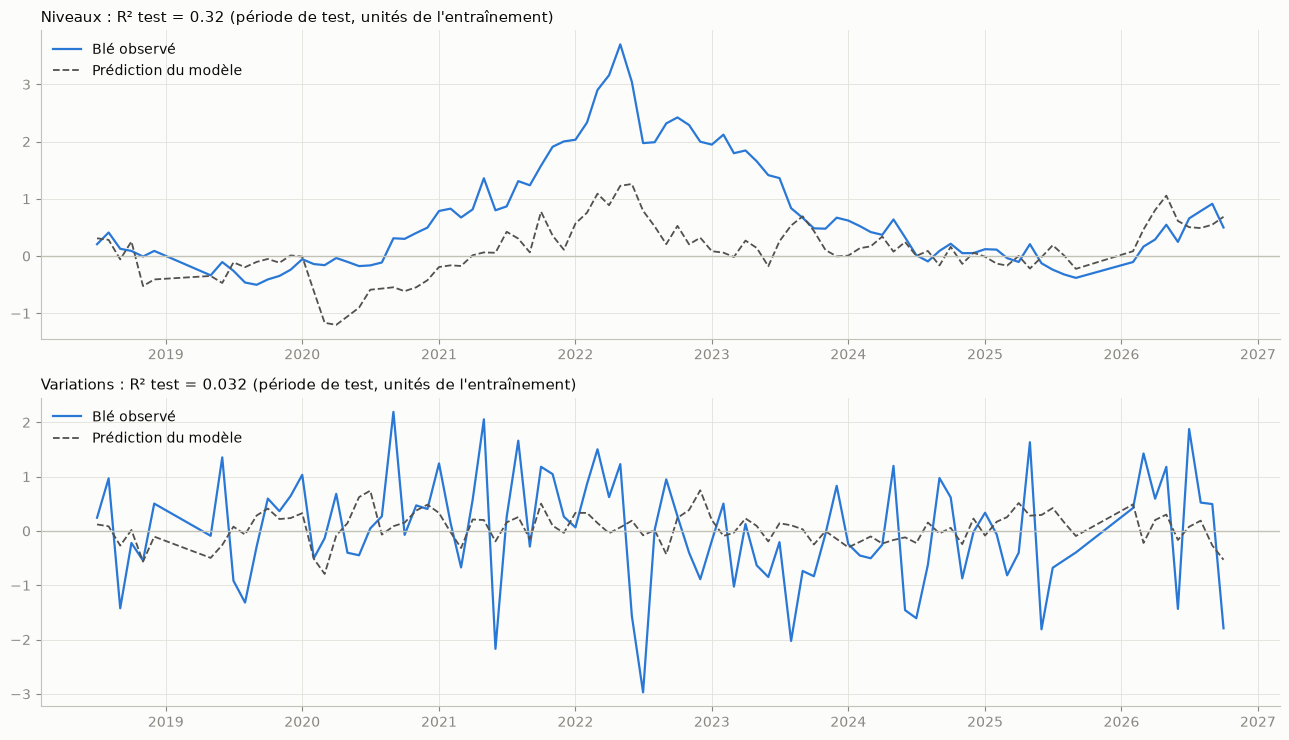

In [19]:
fig, axes = plt.subplots(2, 1, figsize=(13, 7.5))
for ax, y, pred, title in [(axes[0], y_lvl, pred_lvl, f"Niveaux : R² test = {res_lvl['R² test']:.2f}"),
                           (axes[1], y_chg, pred_chg, f"Variations : R² test = {res_chg['R² test']:.3f}")]:
    ax.plot(y.index, y, color=COLORS["wheat_price_usd"], label="Blé observé", lw=1.6)
    ax.plot(pred.index, pred, color=INK2, ls="--", label="Prédiction du modèle", lw=1.3)
    ax.axhline(0, color="#c3c2b7", lw=1)
    ax.set_title(title + " (période de test, unités de l'entraînement)")
    ax.legend(loc="upper left")
fig.tight_layout()
plt.show()